# Network Inference with MIR and APMSD

This tutorial runs the full method of
[Yıldırım & Antonopoulos (2024)](https://doi.org/10.1016/j.chaos.2024.115554) on the
first example of the paper (Section 3.2.1): four coupled logistic maps on a chain
network. The paper reports exact numbers for this case (Table 2 and Figs. 2 and 3), so
every result below can be compared with it.

The method has four steps:

1. Compute the **mutual information rate** (MIR) of every pair of nodes.
2. Generate **amplitude-phase modulated surrogate data** (APMSD): a fraction $pc_{1}$ of
   the instantaneous amplitudes and a fraction $pc_{2}$ of the instantaneous phases of
   each signal are replaced by random values.
3. Test each pair: $H_0$ says the two nodes are not connected. The $p$-value is the
   fraction of surrogates whose MIR is at least the MIR of the data. The
   Benjamini–Hochberg procedure (FDR) corrects for testing many pairs at once.
4. Repeat for an $11 \times 11$ grid of $(pc_{1}, pc_{2})$ and compare each inferred
   network with the true one using TPR and FPR.

In [1]:
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

import complex_network_dynamics as cnd

## The network and the data

The network is a chain of 4 nodes, $1-2-3-4$ (Fig. 2a of the paper). Each node is a
logistic map, $f(x) = r x (1 - x)$ with $r = 4$, coupled as in Eq. (13):

$$
x^i_{n+1} = (1 - \alpha) f(x^i_n) + \frac{\alpha}{k_i} \sum_{j=1}^{N} A_{ij} f(x^j_n),
\qquad \alpha = 0.1 .
$$

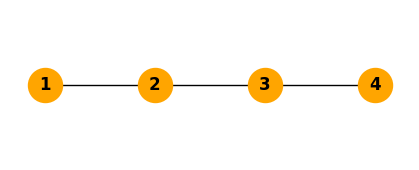

In [2]:
A = np.zeros((4, 4))
for i in range(3):
    A[i, i + 1] = A[i + 1, i] = 1

G = nx.from_numpy_array(A)
plt.figure(figsize=(4, 1.5))
nx.draw(G, pos={i: (i, 0) for i in range(4)}, labels={i: i + 1 for i in range(4)},
        node_color="orange", node_size=600, font_weight="bold")
plt.show()

As in the paper, the first 1293 iterations are dropped as transients (the paper finds
that the maximum Lyapunov exponent has converged by then) and $10^5$ points are
recorded. A positive maximum Lyapunov exponent confirms the dynamics is chaotic; the
paper reports an MLE of about 0.43 (Table 1).

In [3]:
rng = np.random.default_rng(2024)
x0 = rng.random(4)

data, lyapunov = cnd.simulate_discrete_models(
    x0, cnd.logistic, cnd.df_logistic, A, t=100_000, alpha=0.1, n_transient=1293, r=4
)
print("data shape:", data.shape)
print("Lyapunov spectrum:", np.round(lyapunov, 3))

data shape: (100000, 4)
Lyapunov spectrum: [0.43  0.4   0.355 0.283]


## Amplitude correlation and phase synchronisation

Table 1 of the paper describes this system with the mean Pearson correlation of the
pairs (about 0.05) and the Kuramoto order parameter $\rho$ of the Hilbert phases
(0.93). Correlation is weak but the phases are strongly synchronised.

To reproduce these numbers we pass `demean=False` to `hilbert_phases`, as the paper
computed the phases of the raw signals. The maps take values in $[0, 1]$, and the
Hilbert phase of a signal with a nonzero mean hardly moves, so part of this
synchronisation is an artefact of the offset: with the library's default,
`demean=True`, the order parameter is much lower.

In [4]:
pairs = np.triu_indices(4, k=1)
pair_labels = [f"{i + 1}–{j + 1}" for i, j in zip(*pairs)]

R = np.corrcoef(data, rowvar=False)
phases = cnd.hilbert_phases(data, demean=False)  # as in the paper
C = cnd.pairwise_sync(phases)

print(f"mean |R| over pairs: {np.abs(R[pairs]).mean():.3f}")
print(f"Kuramoto order parameter rho: {cnd.global_sync(phases)[-1]:.2f}")

mean |R| over pairs: 0.064
Kuramoto order parameter rho: 0.93


## Pearson correlation cannot find the network, MIR can

In a bar plot of the pairs, a grey band between the connected pairs (purple) and the
unconnected pairs (blue) means some threshold would separate them perfectly.

For Pearson correlation there is no such band (Fig. 2b): the indirect pairs 1–3 and
2–4 are more correlated than the direct pairs 1–2 and 3–4.

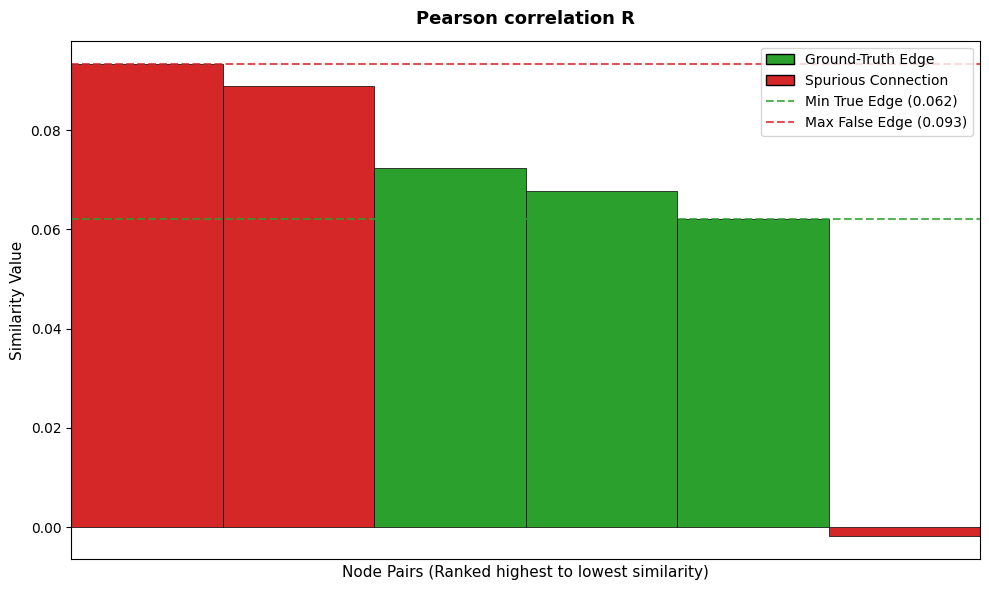

threshold band: None


In [5]:
R_band = cnd.plot_similarity_gap_bars(R, A, title="Pearson correlation R")
print("threshold band:", R_band)

MIR separates the two groups (Fig. 2c): every connected pair has a higher MIR than
every unconnected pair.

MIR of 6 pairs and 1e5 points: 0.32 s


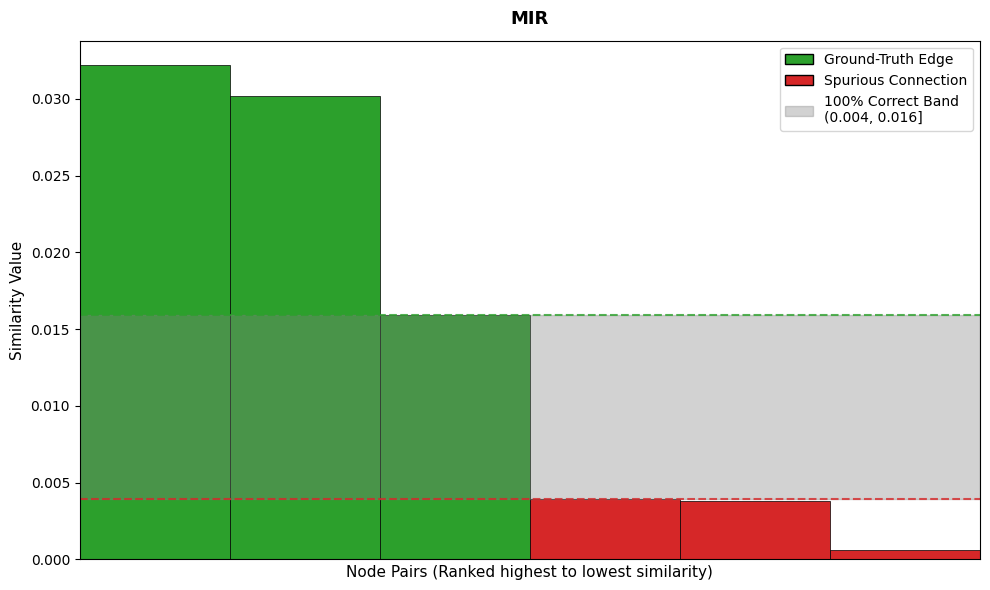

threshold band: (0.00392778581166609, 0.015907373237028854)


In [6]:
start = time.perf_counter()
mir = cnd.MIR(data)[0]
print(f"MIR of 6 pairs and 1e5 points: {time.perf_counter() - start:.2f} s")

mir_band = cnd.plot_similarity_gap_bars(mir, A, title="MIR")
print("threshold band:", mir_band)

A threshold works here because we know the answer. With real data we would not know
where to put it, which is why the method replaces the threshold with a statistical
test against surrogate data.

## One APMSD test: (pc₁, pc₂) = (0, 60)%

The paper shows this pair in Fig. 2c and Table 2: the amplitudes are kept and 60% of
the phases are randomised. A significance level $p_{sl} = 0.1$ means
$\aleph_{SD} = 1/p_{sl} = 10$ surrogates per pair, as in the paper.

`mir_surrogate_test` computes the MIR of the data and of every surrogate, the
$p$-values and the FDR correction, and returns the inferred network. Given the true
network, it also returns TPR and FPR.

In [7]:
mir_all, inferred, rates = cnd.mir_surrogate_test(
    data, p_sl=0.1, true_network=A, pc_amplitude=0.0, pc_phase=0.6, rng=1
)
mir_data, mir_surrogates = mir_all[0, 0], mir_all[0, 1:]   # shapes (6,) and (10, 6)

print("inferred adjacency matrix:")
print(inferred[0].astype(int))
print(f"TPR = {rates[0, 1]:.2f}, FPR = {rates[0, 2]:.2f}")

inferred adjacency matrix:
[[0 1 0 0]
 [1 0 1 0]
 [0 1 0 1]
 [0 0 1 0]]
TPR = 1.00, FPR = 0.00


The inferred network is the chain: perfect inference. The next plot is Fig. 2c of the
paper: the bars are the MIR of the data and the orange points the MIR of the 10
surrogates. Linked pairs lose MIR in the surrogates, while unlinked pairs gain some,
so every linked pair has $p = 0$.

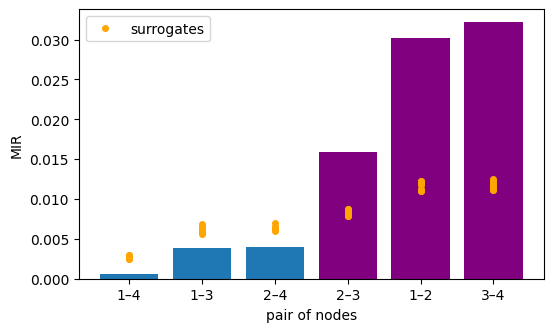

In [8]:
order = np.argsort(mir_data)
linked = A[pairs][order] == 1

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(range(6), mir_data[order], color=np.where(linked, "purple", "tab:blue"))
for k in range(len(mir_surrogates)):
    ax.plot(range(6), mir_surrogates[k, order], "o", color="orange", ms=4,
            label="surrogates" if k == 0 else None)
ax.set_xticks(range(6), np.array(pair_labels)[order])
ax.set_xlabel("pair of nodes")
ax.set_ylabel("MIR")
ax.legend()
plt.show()

### Comparison with Table 2 of the paper

The table puts our values next to the paper's, for the original data and the mean over
the 10 surrogates. The data and the surrogates are random, so the numbers agree to
about two significant figures rather than exactly.

In [9]:
surrogates = cnd.amplitude_phase_surrogates(data, n_surrogates=10, pc_amplitude=0.0, pc_phase=0.6, rng=1)
R_sur = np.mean([np.corrcoef(s, rowvar=False)[pairs] for s in surrogates], axis=0)
C_sur = np.mean([cnd.pairwise_sync(cnd.hilbert_phases(s, demean=False))[pairs] for s in surrogates], axis=0)

paper = pd.DataFrame(
    {
        "R (paper)": [0.056, 0.09, -0.009, 0.06, 0.09, 0.06],
        "MIR (paper)": [0.031, 0.004, 0.0007, 0.016, 0.038, 0.032],
        "C (paper)": [0.8328, 0.8201, 0.7963, 0.8335, 0.82, 0.83],
        "surrogate MIR (paper)": [0.012, 0.0061, 0.0027, 0.008, 0.0064, 0.0118],
        "surrogate R (paper)": [0.12, 0.15, 0.10, 0.13, 0.15, 0.12],
        "surrogate C (paper)": [0.74, 0.74, 0.73, 0.74, 0.74, 0.74],
    },
    index=pair_labels,
)
ours = pd.DataFrame(
    {
        "R": R[pairs],
        "MIR": mir_data,
        "C": C[pairs],
        "surrogate MIR": mir_surrogates.mean(axis=0),
        "surrogate R": R_sur,
        "surrogate C": C_sur,
    },
    index=pair_labels,
)
table = pd.concat([ours, paper], axis=1)[
    ["R", "R (paper)", "MIR", "MIR (paper)", "C", "C (paper)",
     "surrogate MIR", "surrogate MIR (paper)", "surrogate R", "surrogate R (paper)",
     "surrogate C", "surrogate C (paper)"]
]
table.round(4)

,R,R (paper),MIR,MIR (paper),C,C (paper),surrogate MIR,surrogate MIR (paper),surrogate R,surrogate R (paper),surrogate C,surrogate C (paper)
1–2,0.0676,0.056,0.0302,0.0310,0.8346,0.8328,0.0117,0.0120,0.1263,0.12,0.7345,0.74
1–3,0.0889,0.090,0.0038,0.0040,0.8215,0.8201,0.0062,0.0061,0.1526,0.15,0.7346,0.74
1–4,-0.0017,-0.009,0.0006,0.0007,0.7982,0.7963,0.0027,0.0027,0.1010,0.10,0.7202,0.73
2–3,0.0723,0.060,0.0159,0.0160,0.8365,0.8335,0.0084,0.0080,0.1369,0.13,0.7369,0.74
2–4,0.0933,0.090,0.0039,0.0380,0.8212,0.8200,0.0064,0.0064,0.1564,0.15,0.7350,0.74
3–4,0.0621,0.060,0.0322,0.0320,0.8341,0.8300,0.0117,0.0118,0.1237,0.12,0.7340,0.74


The values agree, except the MIR of pair 2–4: Table 2 gives 0.038, which would make it
higher than the connected pair 2–3 and contradict Fig. 2c of the paper and its text. Our
value, about 0.004, is close to the other indirect pair 1–3, so 0.038 is most likely a
typo for 0.0038.

The surrogate columns also show what the phase randomisation does: phase
synchronisation $C$ drops from about 0.82 to about 0.74 for every pair and $R$ rises to
0.10–0.16, matching the surrogate columns of Table 2.

## The $(pc_{1}, pc_{2})$ parameter space

Now repeat the test on the $11 \times 11$ grid $pc_{1}, pc_{2} \in \{0, 10, \dots,
100\}\%$ (Fig. 2d). Each point needs the MIR of 10 surrogates; the whole grid takes a
few minutes.

In [10]:
def apmsd_parameter_space(data, true_network, p_sl=0.1, levels=np.linspace(0, 1, 11), rng=None):
    # TPR and FPR for every (pc_amplitude, pc_phase) on the grid; [i, j] is
    # pc_amplitude = levels[i], pc_phase = levels[j]
    rng = np.random.default_rng(rng)
    tpr = np.zeros((len(levels), len(levels)))
    fpr = np.zeros_like(tpr)
    for i, pc1 in enumerate(levels):
        for j, pc2 in enumerate(levels):
            _, _, rates = cnd.mir_surrogate_test(
                data, p_sl=p_sl, true_network=true_network,
                pc_amplitude=pc1, pc_phase=pc2, rng=rng,
            )
            tpr[i, j], fpr[i, j] = rates[0, 1:]
    return tpr, fpr


def plot_parameter_space(tpr, fpr, levels=np.linspace(0, 1, 11), title=None, ax=None):
    # Colour: TPR. Red circles: FPR > 0 (area grows with FPR). Green: perfect inference.
    ax = ax or plt.gca()
    pct = 100 * levels
    image = ax.pcolormesh(pct, pct, tpr.T, cmap="viridis", vmin=0, vmax=1, shading="nearest")
    P1, P2 = np.meshgrid(pct, pct, indexing="ij")
    wrong = fpr > 0
    ax.scatter(P1[wrong], P2[wrong], s=400 * fpr[wrong], facecolors="none", edgecolors="red", linewidths=1.5)
    perfect = (tpr == 1) & (fpr == 0)
    ax.scatter(P1[perfect], P2[perfect], s=60, color="limegreen", edgecolors="black")
    ax.set_xlabel("$pc_{1}$, amplitudes randomised (%)")
    ax.set_ylabel("$pc_{2}$, phases randomised (%)")
    ax.set_xticks(pct[::2])
    ax.set_yticks(pct[::2])
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)
    return image


start = time.perf_counter()
tpr, fpr = apmsd_parameter_space(data, A, rng=7)
print(f"121 tests in {time.perf_counter() - start:.0f} s")

121 tests in 249 s


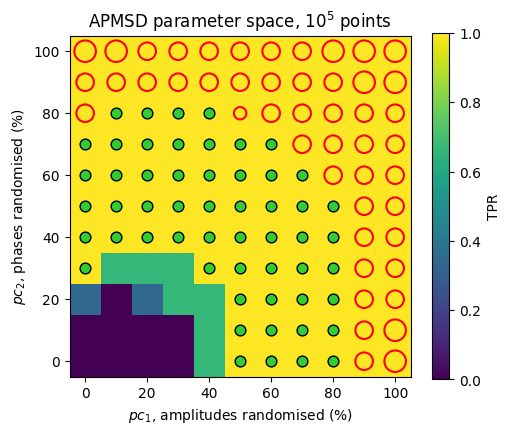

55 of 121 pairs give perfect inference
(0, 60)% perfect: True


In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = plot_parameter_space(tpr, fpr, title="APMSD parameter space, $10^5$ points")
fig.colorbar(image, ax=ax, label="TPR")
plt.show()

levels = np.linspace(0, 1, 11)
perfect = np.argwhere((tpr == 1) & (fpr == 0))
print(f"{len(perfect)} of 121 pairs give perfect inference")
print("(0, 60)% perfect:", bool(tpr[0, 6] == 1 and fpr[0, 6] == 0))

As in Fig. 2d of the paper, many pairs of percentages give perfect inference (green),
and $(0, 60)\%$ is one of them. Along $pc_{2} = 0$ (no phase randomisation) the method
finds no links: these surrogates keep the phase synchronisation that connects the
nodes, so their MIR stays as high as the data's. Exact points can differ from the paper
near the edges of the green region, because the surrogates are random.

### Choosing the best pair

With a known network, the paper picks the pair whose (TPR, FPR) point is closest to
perfect inference, $(1, 0)$, on the ROC plane:
$\tilde d = \sqrt{(1 - \mathrm{TPR})^2 + \mathrm{FPR}^2}$. Here many pairs reach
$\tilde d = 0$, so the first one found is reported.

In [12]:
distance = np.hypot(1 - tpr, fpr)
i, j = np.unravel_index(np.argmin(distance), distance.shape)
print(f"pairs with the smallest distance: {np.sum(distance == distance.min())}")
print(f"first best pair: (pc1, pc2) = ({100 * levels[i]:.0f}, {100 * levels[j]:.0f})%, "
      f"TPR = {tpr[i, j]:.2f}, FPR = {fpr[i, j]:.2f}, d = {distance[i, j]:.2f}")

pairs with the smallest distance: 55
first best pair: (pc1, pc2) = (0, 30)%, TPR = 1.00, FPR = 0.00, d = 0.00


## Down-sampling (Fig. 3)

The paper also asks how few data points the method needs. If the $10^5$ points were
recorded over 10 seconds, the sampling rate is 10 kHz. Keeping every 100th point gives a
100 Hz recording of 1000 points, and every 500th point a 20 Hz recording of 200 points.

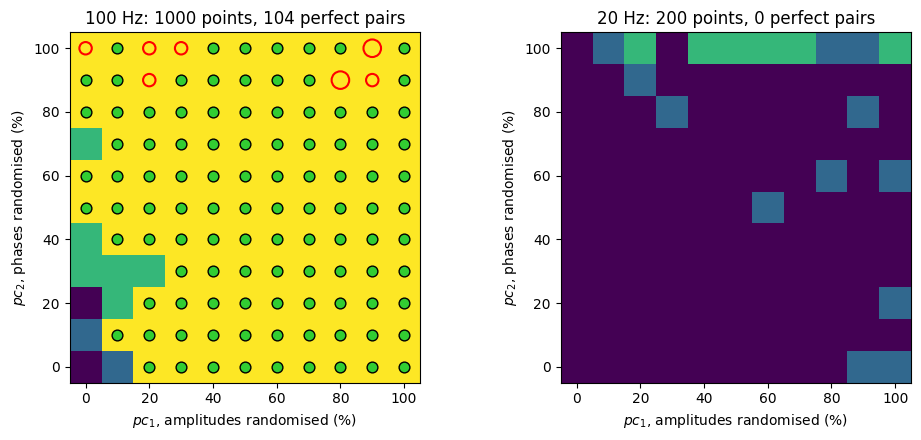

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (step, rate) in zip(axes, [(100, "100 Hz"), (500, "20 Hz")]):
    sample = data[::step]
    tpr_s, fpr_s = apmsd_parameter_space(sample, A, rng=11)
    n_perfect = int(np.sum((tpr_s == 1) & (fpr_s == 0)))
    plot_parameter_space(tpr_s, fpr_s, ax=ax,
                         title=f"{rate}: {len(sample)} points, {n_perfect} perfect pairs")
plt.tight_layout()
plt.show()

At 100 Hz (1000 points) many pairs of percentages still recover the chain exactly. At
20 Hz (200 points) none do here, while Fig. 3c of the paper shows success at 20 Hz and
even 10 Hz. Taking every 500th point of a chaotic map leaves almost independent
samples, and with only 200 of them the MIR estimates are too noisy: the MIR of the
linked pairs is no longer clearly above that of their surrogates, so their $p$-values
are not 0. The paper may have down-sampled differently; the down-sampling script is not
in the thesis code, so this part is not a like-for-like comparison.

## Summary

- MIR finds the structure of this network where Pearson correlation fails.
- APMSD surrogates replace the threshold with a hypothesis test: at
  $(pc_{1}, pc_{2}) = (0, 60)\%$ the test recovers the chain exactly, as in the paper.
- The parameter space shows which mix of amplitude and phase randomisation removes
  the dependence between linked nodes. Here phase randomisation is what matters, which
  fits the strong phase synchronisation ($\rho \approx 0.93$) and weak correlation of
  this system.
- The method still works on down-sampled data of 1000 points; at 200 points this
  implementation does not reproduce the paper's Fig. 3c.

The functions used are documented in the
[Network Inference](../api/network_inference.md),
[Surrogate Data](../api/surrogates.md) and
[Synchronisation](../api/synchronisation.md) API pages.